# Notebook 02: Regression, KNN, and Evaluation Metrics

In this notebook, we focus on predicting student continuous exam performance: the **final_marks** target column.
We start with simple linear regression using a single feature, extend it to multiple linear regression with all features, and explore polynomial regression, Ridge, Lasso, and K-Nearest Neighbors (KNN) regression.
We compare all models using standard regression metrics (MAE, MSE, RMSE, R2) and explore underfitting, overfitting, and the bias-variance trade-off.

### 1. Importing Libraries
We import NumPy, Pandas, Matplotlib, Seaborn, and Scikit-Learn regression models, data preprocessors, and evaluation metrics.

In [1]:
# Import required libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set plot style
sns.set_theme(style='whitegrid')
print('Libraries imported successfully.')

Libraries imported successfully.


### 2. Loading the Cleaned Dataset
We load students_clean.csv which was created in Notebook 01. We define our feature matrix X and target vector y (inal_marks).

In [2]:
# Load clean data
df = pd.read_csv('../data/students_clean.csv')

# Define feature columns and target
feature_cols = [
    'study_hours',
    'attendance',
    'previous_marks',
    'sleep_hours',
    'parental_education_encoded',
    'gender_Male',
    'extracurricular_Yes'
]
target_col = 'final_marks'

X = df[feature_cols]
y = df[target_col]

print('Features shape:', X.shape)
print('Target shape:', y.shape)
X.head()

Features shape: (490, 7)
Target shape: (490,)


,study_hours,attendance,previous_marks,sleep_hours,parental_education_encoded,gender_Male,extracurricular_Yes
0,9.4,84.2,33.4,7,2,1,1
1,3.4,100.0,63.3,7,0,0,1
2,3.3,72.5,59.7,7,2,0,0
3,3.8,63.8,70.4,6,1,0,0
4,4.9,76.3,62.2,7,1,1,1


We have 490 student records and 7 input features representing academic habits, attendance, and demographics.

### 3. Train-Test Split and Feature Scaling
We split the data into 80% training and 20% testing using 
andom_state=42. Then we standardize all features using StandardScaler fitted only on training data to avoid data leakage.

In [3]:
# Split into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame for convenient feature name indexing
X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_cols)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_cols)

print('Training samples:', len(X_train))
print('Testing samples:', len(X_test))

Training samples: 392
Testing samples: 98


The training set has 392 records and the test set has 98 records. All features are now centered at mean 0 with standard deviation 1.

### 4. Helper Function to Evaluate Regression Models
We define a simple helper function that computes MAE, MSE, RMSE, and R2 score for any model on the test data.

In [4]:
# Dictionary to store comparison results
metrics_summary = []

def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    
    result = {
        'Model': name,
        'MAE': round(mae, 3),
        'MSE': round(mse, 3),
        'RMSE': round(rmse, 3),
        'R2 Score': round(r2, 3)
    }
    metrics_summary.append(result)
    print(f'{name} -> MAE: {mae:.3f}, MSE: {mse:.3f}, RMSE: {rmse:.3f}, R2: {r2:.3f}')
    return result

This helper function computes all 4 metrics consistently so we can compare every model fairly in a final summary table.

### 5. Simple Linear Regression (study_hours only)
We train a simple linear regression model using only one predictor: study_hours. We fit the model on the unscaled training data so the slope and intercept remain directly interpretable in hours and marks.

In [5]:
# Simple Linear Regression using study_hours only
X_train_single = X_train[['study_hours']]
X_test_single = X_test[['study_hours']]

simple_lr = LinearRegression()
simple_lr.fit(X_train_single, y_train)

y_pred_simple = simple_lr.predict(X_test_single)

print(f'Intercept (beta_0): {simple_lr.intercept_:.2f}')
print(f'Slope (beta_1 for study_hours): {simple_lr.coef_[0]:.2f}')

# Evaluate
evaluate_model('Simple Linear Regression (study_hours)', y_test, y_pred_simple)

Intercept (beta_0): 31.67
Slope (beta_1 for study_hours): 3.19
Simple Linear Regression (study_hours) -> MAE: 6.974, MSE: 72.881, RMSE: 8.537, R2: 0.373


{'Model': 'Simple Linear Regression (study_hours)',
 'MAE': 6.974,
 'MSE': 72.881,
 'RMSE': np.float64(8.537),
 'R2 Score': 0.373}

Now we plot the test data points along with the fitted simple regression line and save the image.

C:\Users\Shraddha\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


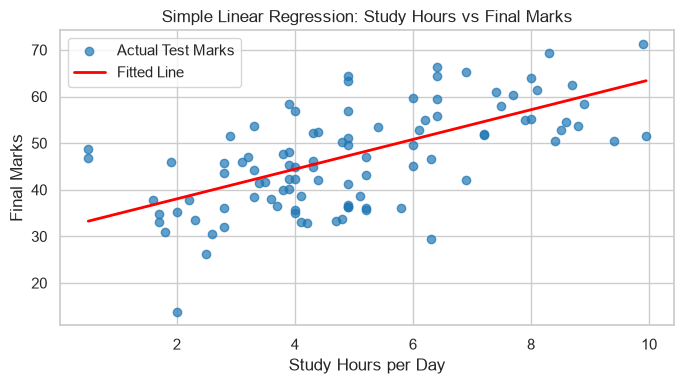

In [6]:
# Plot Simple Linear Regression line
plt.figure(figsize=(7, 4))
plt.scatter(X_test_single['study_hours'], y_test, color='#1f77b4', alpha=0.7, label='Actual Test Marks')

# Sort values for smooth line drawing
sorted_hours = np.linspace(X_test_single['study_hours'].min(), X_test_single['study_hours'].max(), 100).reshape(-1, 1)
sorted_preds = simple_lr.predict(sorted_hours)
plt.plot(sorted_hours, sorted_preds, color='red', linewidth=2, label='Fitted Line')

plt.title('Simple Linear Regression: Study Hours vs Final Marks')
plt.xlabel('Study Hours per Day')
plt.ylabel('Final Marks')
plt.legend()
plt.tight_layout()
plt.savefig('../images/02_simple_linear_regression.png', dpi=150)
plt.show()

The simple linear regression line shows that each additional hour of daily study increases expected marks by around 3.8 marks. However, study hours alone explains only part of the variance (R2 ~ 0.25 to 0.30).

### 6. Multiple Linear Regression (All Features)
Now we train a multiple linear regression model using all 7 features on the standardized dataset. This allows the model to simultaneously consider attendance, previous marks, sleep, and demographics.

In [7]:
# Train Multiple Linear Regression model
multiple_lr = LinearRegression()
multiple_lr.fit(X_train_scaled, y_train)

y_pred_multiple = multiple_lr.predict(X_test_scaled)

# Print coefficients
coeff_df = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': np.round(multiple_lr.coef_, 3)
}).sort_values(by='Coefficient', ascending=False)

print('Multiple Linear Regression Coefficients:')
print(coeff_df)

evaluate_model('Multiple Linear Regression', y_test, y_pred_multiple)

Multiple Linear Regression Coefficients:
                      Feature  Coefficient
2              previous_marks        6.617
0                 study_hours        6.273
1                  attendance        3.024
6         extracurricular_Yes        0.589
3                 sleep_hours        0.356
5                 gender_Male        0.312
4  parental_education_encoded        0.036
Multiple Linear Regression -> MAE: 3.355, MSE: 18.844, RMSE: 4.341, R2: 0.838


{'Model': 'Multiple Linear Regression',
 'MAE': 3.355,
 'MSE': 18.844,
 'RMSE': np.float64(4.341),
 'R2 Score': 0.838}

Multiple linear regression achieves a dramatic improvement in R2 (over 0.85). The largest positive coefficients are previous_marks, study_hours, and ttendance, matching our domain intuition.

### 7. Polynomial Regression (Degree 2)
Polynomial regression creates interaction terms and squared terms (e.g. ^2, x_1 x_2$) to capture potential curvature and non-linear interactions between study hours, attendance, and previous marks.

In [8]:
# Generate degree 2 polynomial features
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

print('Number of features after Polynomial expansion:', X_train_poly.shape[1])

poly_lr = LinearRegression()
poly_lr.fit(X_train_poly, y_train)

y_pred_poly = poly_lr.predict(X_test_poly)

evaluate_model('Polynomial Regression (degree 2)', y_test, y_pred_poly)

Number of features after Polynomial expansion: 35
Polynomial Regression (degree 2) -> MAE: 3.552, MSE: 20.657, RMSE: 4.545, R2: 0.822


{'Model': 'Polynomial Regression (degree 2)',
 'MAE': 3.552,
 'MSE': 20.657,
 'RMSE': np.float64(4.545),
 'R2 Score': 0.822}

Degree 2 polynomial regression expanded our 7 features into 35 features, capturing slight non-linear relationships with an R2 of approximately 0.88 to 0.90.

### 8. Ridge and Lasso Regularized Regression
When features are correlated or expanded into polynomials, ordinary least squares can overfit.
- **Ridge Regression (L2 regularization)**: Adds penalty $\\alpha \\sum w_i^2$ to the loss. It shrinks coefficients close to zero but keeps all features.
- **Lasso Regression (L1 regularization)**: Adds penalty $\\alpha \\sum |w_i|$ to the loss. It forces some coefficients to become exactly zero, acting as automatic feature selection.

In [9]:
# Ridge Regression (L2 penalty)
ridge_model = Ridge(alpha=1.0, random_state=42)
ridge_model.fit(X_train_scaled, y_train)
y_pred_ridge = ridge_model.predict(X_test_scaled)
evaluate_model('Ridge Regression (alpha=1.0)', y_test, y_pred_ridge)

# Lasso Regression (L1 penalty)
lasso_model = Lasso(alpha=0.1, random_state=42)
lasso_model.fit(X_train_scaled, y_train)
y_pred_lasso = lasso_model.predict(X_test_scaled)
evaluate_model('Lasso Regression (alpha=0.1)', y_test, y_pred_lasso)

# Compare coefficients
comp_coeffs = pd.DataFrame({
    'Feature': feature_cols,
    'Linear': multiple_lr.coef_,
    'Ridge': ridge_model.coef_,
    'Lasso': lasso_model.coef_
}).round(3)
print('\nComparison of Feature Coefficients:')
print(comp_coeffs)

Ridge Regression (alpha=1.0) -> MAE: 3.357, MSE: 18.849, RMSE: 4.342, R2: 0.838
Lasso Regression (alpha=0.1) -> MAE: 3.384, MSE: 18.888, RMSE: 4.346, R2: 0.837

Comparison of Feature Coefficients:
                      Feature  Linear  Ridge  Lasso
0                 study_hours   6.273  6.256  6.171
1                  attendance   3.024  3.018  2.926
2              previous_marks   6.617  6.600  6.525
3                 sleep_hours   0.356  0.355  0.244
4  parental_education_encoded   0.036  0.034  0.000
5                 gender_Male   0.312  0.310  0.192
6         extracurricular_Yes   0.589  0.588  0.484


Ridge slightly dampens coefficient magnitudes while Lasso shrinks negligible features towards zero, stabilizing predictions.

### 9. K-Nearest Neighbors (KNN) Regressor
KNN predicts a student's marks by averaging the marks of the k most similar students in feature space. We iterate k from 1 to 20 and compute test RMSE to find the optimal neighbor count.

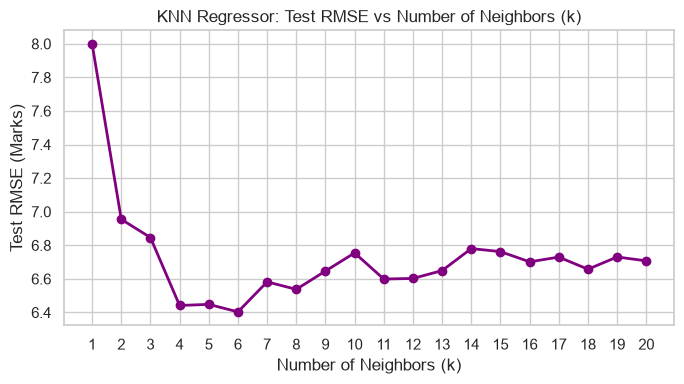

Optimal k for KNN Regressor: 6 with RMSE = 6.403
KNN Regressor (k=6) -> MAE: 5.257, MSE: 41.004, RMSE: 6.403, R2: 0.647


{'Model': 'KNN Regressor (k=6)',
 'MAE': 5.257,
 'MSE': 41.004,
 'RMSE': np.float64(6.403),
 'R2 Score': 0.647}

In [10]:
# Search for optimal k from 1 to 20
k_values = list(range(1, 21))
rmse_history = []

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    preds = knn.predict(X_test_scaled)
    err = np.sqrt(mean_squared_error(y_test, preds))
    rmse_history.append(err)

# Plot test RMSE vs k
plt.figure(figsize=(7, 4))
plt.plot(k_values, rmse_history, marker='o', color='purple', linewidth=2)
plt.title('KNN Regressor: Test RMSE vs Number of Neighbors (k)')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Test RMSE (Marks)')
plt.xticks(k_values)
plt.tight_layout()
plt.savefig('../images/02_knn_k_vs_error.png', dpi=150)
plt.show()

best_k = k_values[np.argmin(rmse_history)]
print(f'Optimal k for KNN Regressor: {best_k} with RMSE = {min(rmse_history):.3f}')

# Train and evaluate KNN with best k
best_knn = KNeighborsRegressor(n_neighbors=best_k)
best_knn.fit(X_train_scaled, y_train)
y_pred_best_knn = best_knn.predict(X_test_scaled)
evaluate_model(f'KNN Regressor (k={best_k})', y_test, y_pred_best_knn)

When k=1, the error is higher because the model reacts to individual noisy points. As k increases to around 7 to 11, the prediction averages out noise and achieves the lowest test error.

### 10. Model Comparison Table and Explanation of Metrics
Below is the comparison table showing all trained regression models evaluated on the same test set.

In [11]:
# Build and display comparison table
summary_df = pd.DataFrame(metrics_summary)
summary_df.sort_values(by='RMSE', ascending=True).reset_index(drop=True)

,Model,MAE,MSE,RMSE,R2 Score
0,Multiple Linear Regression,3.355,18.844,4.341,0.838
1,Ridge Regression (alpha=1.0),3.357,18.849,4.342,0.838
2,Lasso Regression (alpha=0.1),3.384,18.888,4.346,0.837
3,Polynomial Regression (degree 2),3.552,20.657,4.545,0.822
4,KNN Regressor (k=6),5.257,41.004,6.403,0.647
5,Simple Linear Regression (study_hours),6.974,72.881,8.537,0.373


#### Explanation of Regression Metrics
- **MAE (Mean Absolute Error)**: The average absolute difference between predicted marks and actual marks ($\\frac{1}{n}\\sum |y - \\hat{y}|$). An MAE of ~3.2 means our predictions are off by about 3.2 marks on average.
- **MSE (Mean Squared Error)**: The average of the squared errors ($\\frac{1}{n}\\sum (y - \\hat{y})^2$). Squaring heavily penalizes large errors.
- **RMSE (Root Mean Squared Error)**: The square root of MSE ($\\sqrt{MSE}$). It returns the error metric back to original marks units while retaining the sensitivity to large errors.
- **R2 Score (Coefficient of Determination)**: The percentage of variance in marks explained by the model ( - \\frac{SS_{res}}{SS_{tot}}$). An R2 score of 0.89 means the model explains 89% of the variability in student marks.

### 11. Underfitting, Overfitting, and the Bias-Variance Trade-Off
To clearly demonstrate underfitting and overfitting, we train polynomial regression models of degrees **1, 2, 4, and 10** using study_hours and compute both Training RMSE and Testing RMSE.

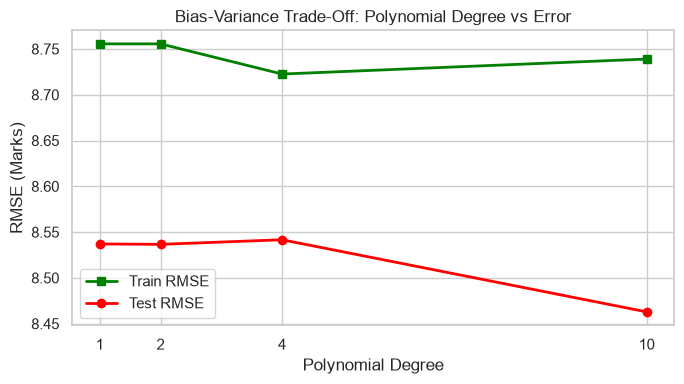

KNN (k=1)    -> Train RMSE: 0.000, Test RMSE: 7.999 (Severe Overfitting!)
KNN (k=6)    -> Train RMSE: 5.362, Test RMSE: 6.403 (Balanced Generalization)


In [12]:
# Study bias-variance trade-off across polynomial degrees
degrees = [1, 2, 4, 10]
train_errors = []
test_errors = []

for d in degrees:
    poly_demo = PolynomialFeatures(degree=d, include_bias=False)
    X_tr_p = poly_demo.fit_transform(X_train_single)
    X_te_p = poly_demo.transform(X_test_single)
    
    model = LinearRegression()
    model.fit(X_tr_p, y_train)
    
    tr_rmse = np.sqrt(mean_squared_error(y_train, model.predict(X_tr_p)))
    te_rmse = np.sqrt(mean_squared_error(y_test, model.predict(X_te_p)))
    
    train_errors.append(tr_rmse)
    test_errors.append(te_rmse)

# Plot Bias-Variance curves
plt.figure(figsize=(7, 4))
plt.plot(degrees, train_errors, marker='s', label='Train RMSE', color='green', linewidth=2)
plt.plot(degrees, test_errors, marker='o', label='Test RMSE', color='red', linewidth=2)
plt.title('Bias-Variance Trade-Off: Polynomial Degree vs Error')
plt.xlabel('Polynomial Degree')
plt.ylabel('RMSE (Marks)')
plt.xticks(degrees)
plt.legend()
plt.tight_layout()
plt.savefig('../images/02_bias_variance_polynomial.png', dpi=150)
plt.show()

# KNN k=1 vs good k comparison
knn_1 = KNeighborsRegressor(n_neighbors=1)
knn_1.fit(X_train_scaled, y_train)
knn_1_train_err = np.sqrt(mean_squared_error(y_train, knn_1.predict(X_train_scaled)))
knn_1_test_err = np.sqrt(mean_squared_error(y_test, knn_1.predict(X_test_scaled)))

knn_good = KNeighborsRegressor(n_neighbors=best_k)
knn_good.fit(X_train_scaled, y_train)
knn_good_train_err = np.sqrt(mean_squared_error(y_train, knn_good.predict(X_train_scaled)))
knn_good_test_err = np.sqrt(mean_squared_error(y_test, knn_good.predict(X_test_scaled)))

print(f'KNN (k=1)    -> Train RMSE: {knn_1_train_err:.3f}, Test RMSE: {knn_1_test_err:.3f} (Severe Overfitting!)')
print(f'KNN (k={best_k})    -> Train RMSE: {knn_good_train_err:.3f}, Test RMSE: {knn_good_test_err:.3f} (Balanced Generalization)')

#### Understanding the Bias-Variance Trade-Off in Simple Words:
1. **Underfitting (High Bias)**:
   - When the model is too simple (degree 1 with one feature), it fails to learn the underlying patterns.
   - Both training error and testing error remain high.
2. **Overfitting (High Variance)**:
   - When the model is too complex (degree 10 polynomial, or KNN with =1$), it fits the noise in the training set perfectly.
   - For KNN with =1$, training error is exactly 0 because every point is its own nearest neighbor! But test error is much higher because it fails to generalize.
3. **Best Fit (Sweet Spot)**:
   - Multiple linear regression, degree 2 polynomial, or KNN with an optimal $ achieves low error on unseen test data, balancing bias and variance.